In [ ]:
'''
okay so thee list of what light curves in her package have >30 candidates. i need a function that:
-looks at all the light curves that i send to fed
if not in average, puts it in average
-finds the relevant data frame
(check whether num in file in star is there)
save num in file in star to a new data frame with the other relevant info
'''

In [110]:
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt

In [78]:
lcfilenames.loc[0, 'filename'][11:50]

'ztf_20221020138241_000686_zi_c01_x_0003'

In [79]:
lcfilenames.loc[0, 'filename'][51]

'1'

In [74]:
lcfilenames.loc[0, 'filename']

'lightcurve_ztf_20221020138241_000686_zi_c01_x_0003_1_1783_1737.csv'

In [14]:
np.unique(lcfilenames['filename'])

array(['lightcurve_ztf_20221020138241_000686_zi_c01_x_0000_1_0141_0231.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c01_x_0000_1_0454_2067.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c01_x_0000_1_0762_0373.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c01_x_0000_1_0799_2018.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c01_x_0000_1_1179_0713.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c01_x_0000_1_1266_0101.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c01_x_0000_1_1332_2797.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c01_x_0000_1_1463_1396.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c01_x_0000_1_1482_1842.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c01_x_0000_1_1569_0222.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c01_x_0000_1_1693_2913.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c01_x_0000_1_1810_1453.csv',
       'lightcurve_ztf_20221020138241_000686_zi_c01_x_0000_1_1863_1666.csv',

In [15]:
#they need to look like they do in the data direc /1020
lcfilenames = pd.read_csv('/home/3155/rwe/filenames_lcs.txt', sep=" ", header=None)
lcfilenames.columns = ["filename"]
filelist = []
for filename in lcfilenames['filename']:
    file = filename[11:50]+'.fits.fz'
    filelist.append(file)
filelist = np.unique(filelist)
    

In [45]:
lcfilenames['filename'][0][-13:-9]

'1783'

In [86]:


lcpath = '/lustre/lrspec/ZTF_data/lightcurves/1020/'
lcfilenames = pd.read_csv('/home/3155/rwe/filenames_lcs.txt', sep=" ", header=None)
lcfilenames.columns = ["filename"] #READ IT

paths = ["/lustre/lrspec/ZTF_data/science_extractions/actually_training/predsarrays_offset_sat_newhparam_b50_allstamps_satdumbsplit_folds_0/",
         "/lustre/lrspec/ZTF_data/science_extractions/actually_training/predsarrays_offset_sat_newhparam_b50_allstamps_satdumbsplit_folds_1/",
         "/lustre/lrspec/ZTF_data/science_extractions/actually_training/predsarrays_offset_sat_newhparam_b50_allstamps_satdumbsplit_folds_2/",
         "/lustre/lrspec/ZTF_data/science_extractions/actually_training/predsarrays_offset_sat_newhparam_b50_allstamps_satdumbsplit_folds_3/",
         "/lustre/lrspec/ZTF_data/science_extractions/actually_training/predsarrays_offset_sat_newhparam_b50_allstamps_satdumbsplit_folds_4/",
]

savedir = "/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/"
trainingdir = '/lustre/lrspec/ZTF_data/science_extractions/actually_training/average/'
alist = []
for filename in lcfilenames['filename']:
    averagefile = filename[11:50]+'._extraction_predsarray_'+filename[51]+'_predsarray.npy'
    # break
    if (os.path.exists(os.path.join(paths[0],averagefile))==True)*(os.path.exists(os.path.join(trainingdir,averagefile))==False):
                #adding average to the ones in training if we need to
                arrays = []
                for path in paths:
                    arrays.append(np.load(path+averagefile))
                average = np.average(arrays, axis=0)
                np.save(os.path.join(trainingdir,averagefile), average)
                print("saved")
    if (os.path.exists(os.path.join(savedir,averagefile))==False)*(os.path.exists(os.path.join(trainingdir,averagefile))==False):
        #iif not in either of them:
        print("still missing "+averagefile)
    # else:
        # onelist.append(averagefile)
    try:    
        df= pd.read_csv(savedir+filename[11:50]+'._'+filename[51]+'_alllist_matched_diffcut5_size1_dedup')
        xcoord = int(filename[-13:-9])
        ycoord= int(filename[-8:-4])
        df = df[(df['closest_x']==xcoord)*(df['closest_y']==ycoord)]
        alist.append([filename, len(df)])
    except:
        if os.path.exists(os.path.join(trainingdir,averagefile))==True:
            # continue
            # print(trainingdir+filename[11:50]+'._'+filename[51]+'_alllist_matched_diffcut5_size1_dedup')
            df= pd.read_csv(trainingdir+filename[11:50]+'._'+filename[51]+'_alllist_matched_diffcut5_size1_dedup')
            xcoord = int(filename[-13:-9])
            ycoord= int(filename[-8:-4])
            df = df[(df['closest_x']==xcoord)*(df['closest_y']==ycoord)]
            alist.append([filename, len(df)])
        
        # 
        # if 
        # except:
        else:
            try:
                alllist = pd.read_csv(savedir+filename[11:50]+'._'+filename[51]+'_alllist_matched')
                print(len(alllist))
                alist.append([filename, 0])
            except:
                predsarray = np.load(os.path.join(savedir,averagefile))
                if (np.max(predsarray[:,1])<=.99)*(np.max(predsarray[:,2])<=.99):
                    print("nothing in here: "+filename)
                    alist.append([filename, 0])
                else:
                    print("didnt fix this one "+filename)
        
    # print(df)
    # break
        
    
                
#     if os.path.exists(os.path.join(savedir,averagefile))==False: #see if it already exists
#         if os.path.exists(os.path.join(trainingdir,averagefile))==False:
#             if np.sum([os.path.exists(os.path.join(paths[i],averagefile)) for i in range(1,5)])==4: 
#                 #if  all 5 done
#                 arrays = []
#                 for path in paths:
#                     arrays.append(np.load(path+averagefile))
#                 average = np.average(arrays, axis=0)
#                 np.save(os.path.join(trainingdir,averagefile), average)
#                 print("saved")
#             else:
#                 print("NOT DONE")
#     # else:   
        # print("NOT DONE")
    # else:
            
    # break


3
2
2
5
1
0
nothing in here: lightcurve_ztf_20221020297847_000449_zr_c08_x_0011_2_0322_1016.csv
nothing in here: lightcurve_ztf_20221020297847_000449_zr_c08_x_0003_2_2997_0219.csv
nothing in here: lightcurve_ztf_20221020297847_000449_zr_c08_x_0008_2_1052_2182.csv
1
0
0
nothing in here: lightcurve_ztf_20221020297847_000449_zr_c08_x_0008_2_2798_0857.csv
nothing in here: lightcurve_ztf_20221020297847_000449_zr_c08_x_0014_2_3059_1725.csv
nothing in here: lightcurve_ztf_20221020297847_000449_zr_c08_x_0020_2_2047_1733.csv
nothing in here: lightcurve_ztf_20221020297847_000449_zr_c08_x_0028_2_1350_2959.csv
0
3
3
1


In [70]:
np.max(theone[:,1])

0.9936827

In [88]:
pd.DataFrame(alist)

,0,1
0,lightcurve_ztf_20221020138241_000686_zi_c01_x_...,1
1,lightcurve_ztf_20221020138241_000686_zi_c01_x_...,1
2,lightcurve_ztf_20221020138241_000686_zi_c01_x_...,1
3,lightcurve_ztf_20221020138241_000686_zi_c01_x_...,0
4,lightcurve_ztf_20221020138241_000686_zi_c01_x_...,1
...,...,...
362,lightcurve_ztf_20221020297847_000449_zr_c02_x_...,0
363,lightcurve_ztf_20221020297847_000449_zr_c02_x_...,0
364,lightcurve_ztf_20221020297847_000449_zr_c02_x_...,0
365,lightcurve_ztf_20221020297847_000449_zr_c02_x_...,0


In [90]:
pd.DataFrame(alist).sort_values(1)[::-1]

,0,1
325,lightcurve_ztf_20221020294271_000449_zr_c09_x_...,23
151,lightcurve_ztf_20221020154120_000640_zi_c04_x_...,21
150,lightcurve_ztf_20221020154120_000640_zi_c04_x_...,20
333,lightcurve_ztf_20221020297847_000449_zr_c16_x_...,13
125,lightcurve_ztf_20221020148032_000686_zg_c12_x_...,12
...,...,...
228,lightcurve_ztf_20221020154120_000640_zi_c13_x_...,0
229,lightcurve_ztf_20221020154120_000640_zi_c13_x_...,0
230,lightcurve_ztf_20221020154120_000640_zi_c13_x_...,0
231,lightcurve_ztf_20221020154120_000640_zi_c13_x_...,0


num candidates below:  0


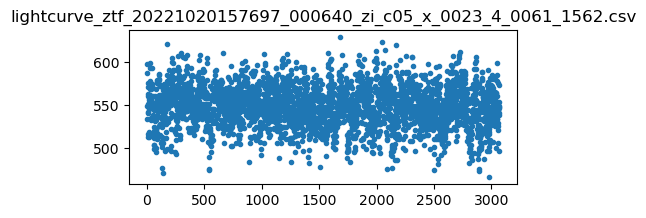

num candidates below:  0


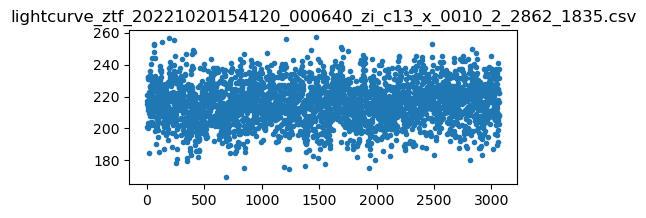

num candidates below:  0


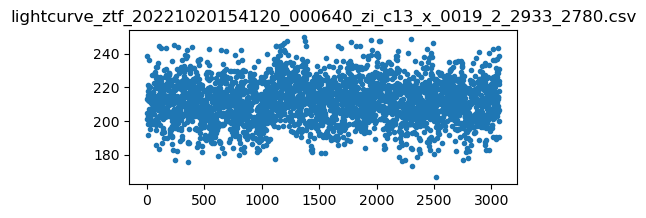

num candidates below:  0


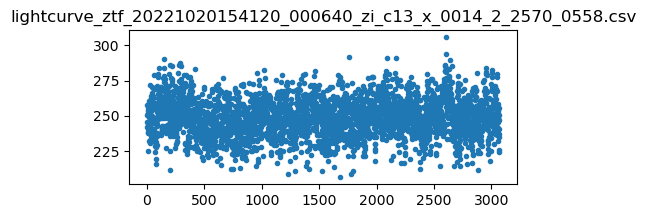

num candidates below:  0


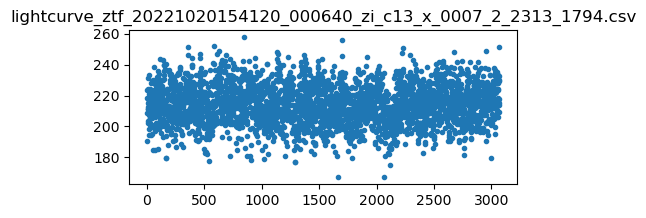

num candidates below:  0


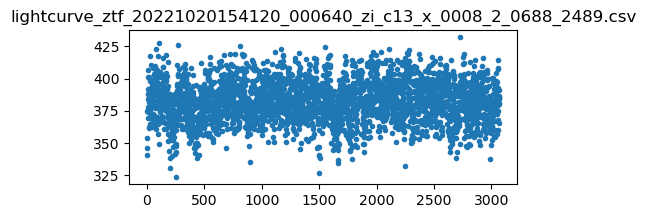

num candidates below:  0


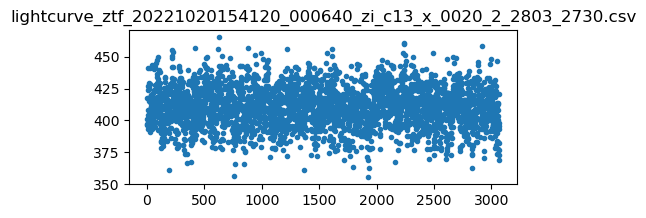

num candidates below:  0


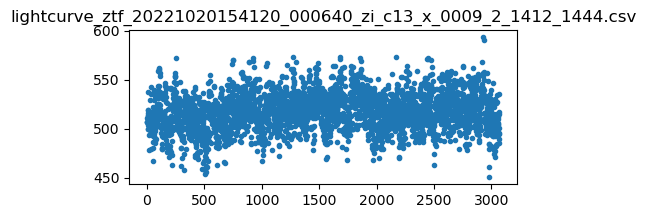

num candidates below:  0


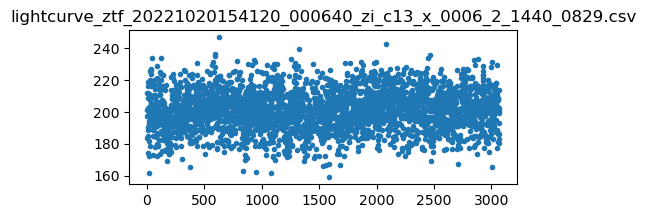

num candidates below:  0


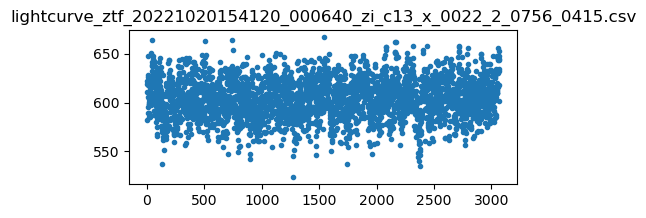

num candidates below:  0


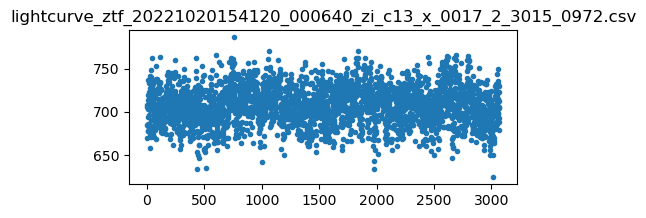

num candidates below:  0


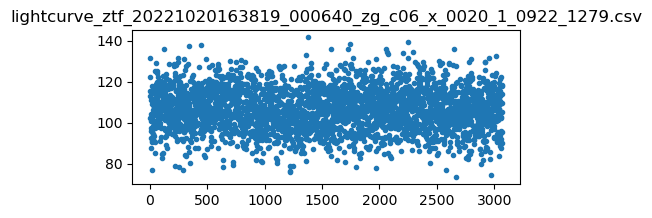

num candidates below:  0


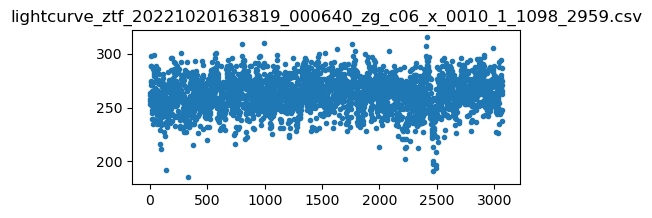

num candidates below:  0


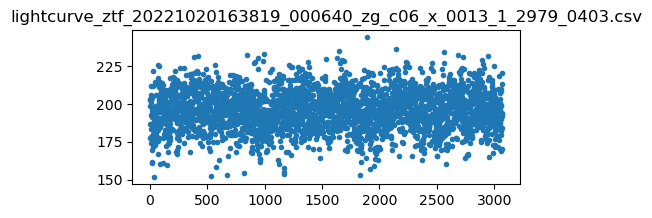

num candidates below:  0


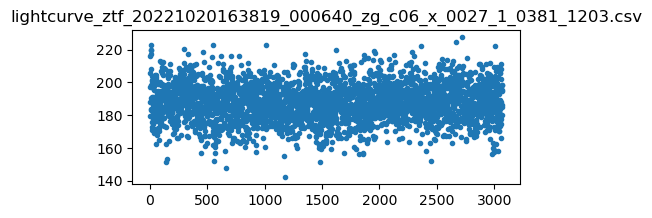

num candidates below:  0


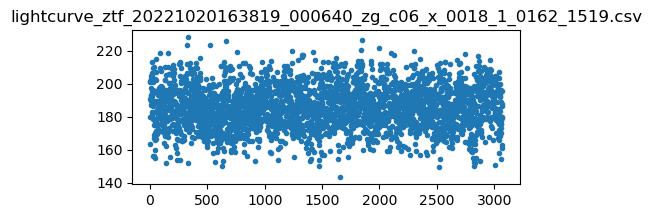

num candidates below:  0


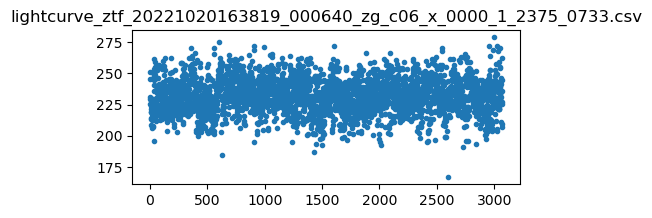

num candidates below:  0


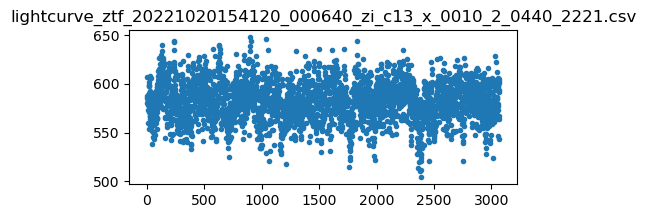

num candidates below:  0


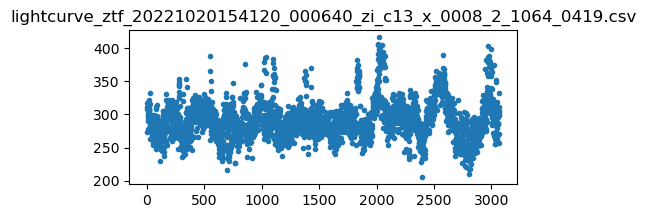

num candidates below:  0


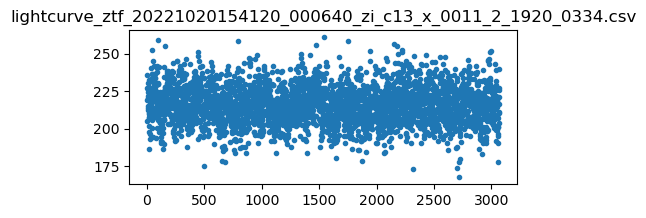

num candidates below:  0


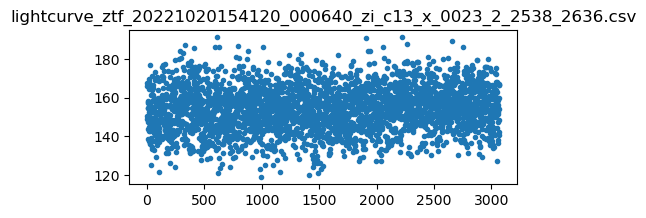

num candidates below:  0


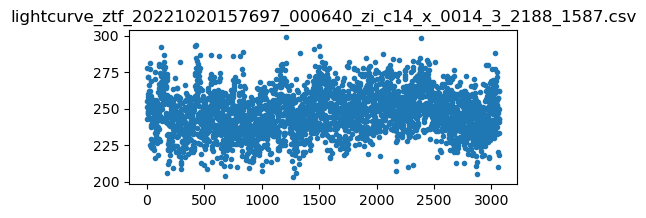

num candidates below:  0


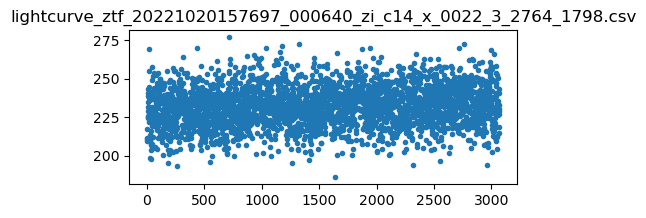

num candidates below:  0


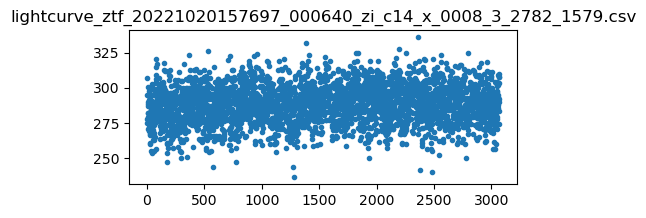

num candidates below:  0


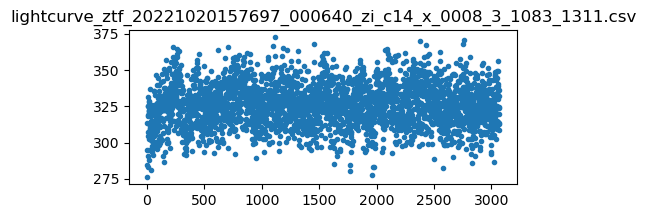

num candidates below:  0


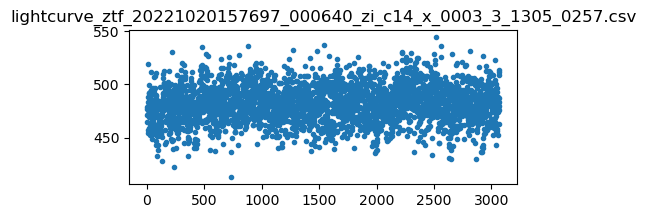

num candidates below:  0


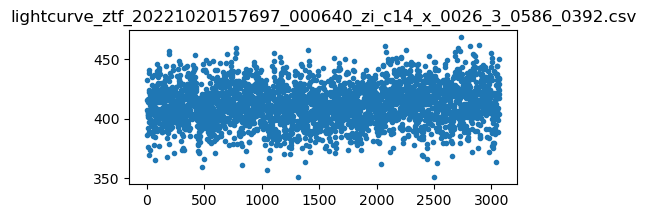

num candidates below:  0


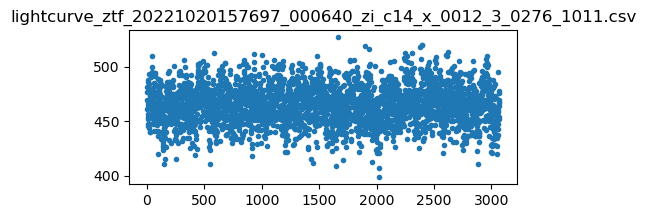

num candidates below:  0


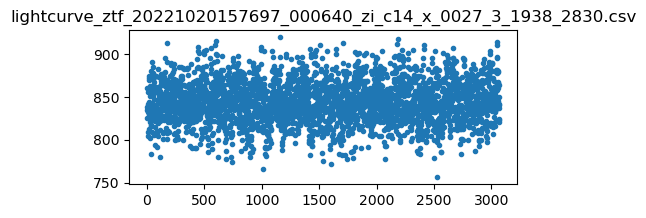

num candidates below:  0


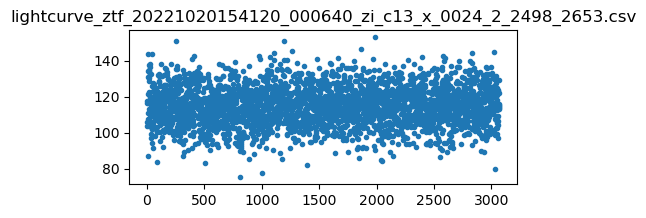

In [150]:
plt.rcParams["figure.figsize"] = (5, 2)
for i, lightcurve in pd.DataFrame(alist).sort_values(1, ascending=True)[:30].iterrows():
        print("num candidates below: ",lightcurve[1] )
        try:
            loaded = pd.read_csv(lcpath+lightcurve[0])
            plt.plot(loaded['flux_hap_2'][:-10], '.')
            plt.title(lightcurve[0])
            plt.show()
            # break
        except:
            # break
            print(lightcurve[0])
        # plt.show()


In [124]:
from astropy.io import fits

In [131]:
len('lightcurve_ztf_20221020138241_000686_zi_c01_x_0000')

50

In [146]:
loaded

,position_id,x_input,y_input,row_index,flux_hap_2,flux_hap_3,flux_hap_4,flux_hap_5,max_col
0,1,2901.0,180.0,0,1281.533691,2241.568359,3242.476562,4268.554688,2901.0
1,1,2901.0,180.0,1,1282.480835,2245.417725,3250.018311,4267.902832,2901.0
2,1,2901.0,180.0,2,1282.580566,2247.608643,3247.244141,4270.875977,2901.0
3,1,2901.0,180.0,3,1301.654907,2289.613281,3322.390381,4381.347168,2901.0
4,1,2901.0,180.0,4,1249.364258,2182.918457,3161.558838,4157.332520,2901.0
...,...,...,...,...,...,...,...,...,...
3075,1,2901.0,180.0,3075,1392.962769,2377.573242,3392.495361,4424.908203,2902.0
3076,1,2901.0,180.0,3076,1360.005127,2279.579102,3236.333496,4214.933594,2902.0
3077,1,2901.0,180.0,3077,1326.426636,2227.615479,3167.904785,4121.047852,2902.0
3078,1,2901.0,180.0,3078,1352.872925,2277.963623,3235.495850,4215.375977,2902.0


In [149]:
plt.close()

/tmp/ipykernel_50011/2910403860.py:11: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(1, 2, figsize=(10,2))


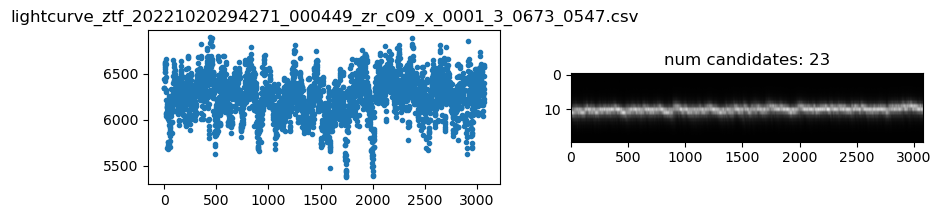

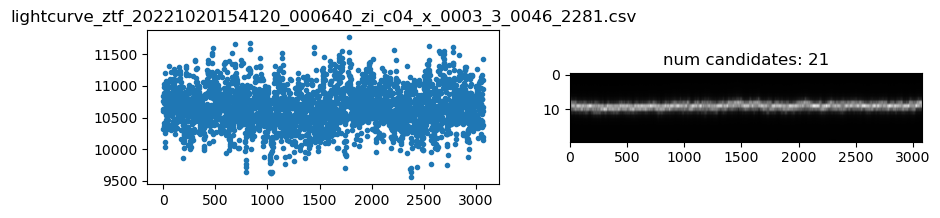

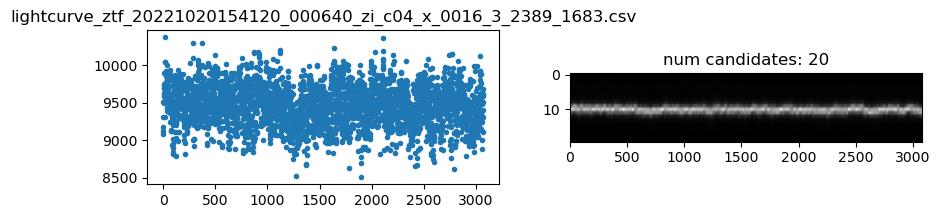

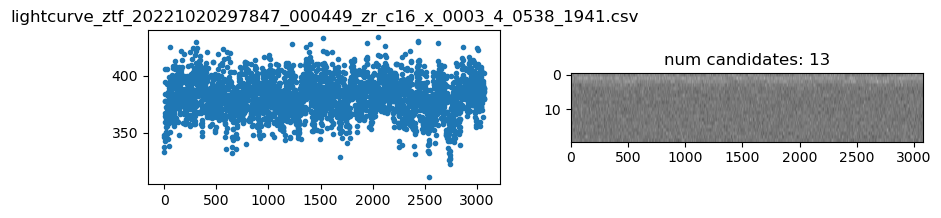

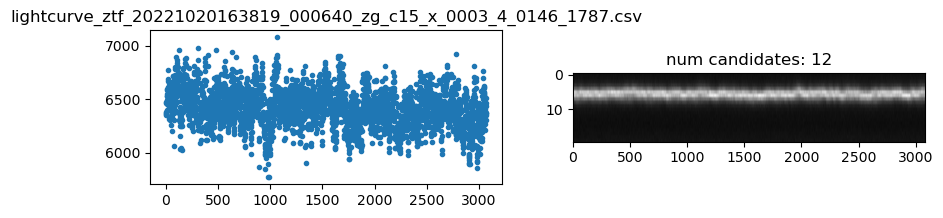

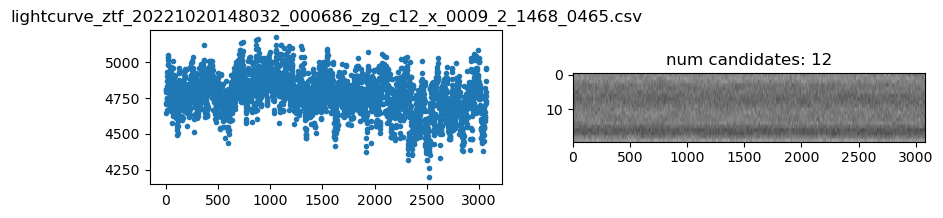

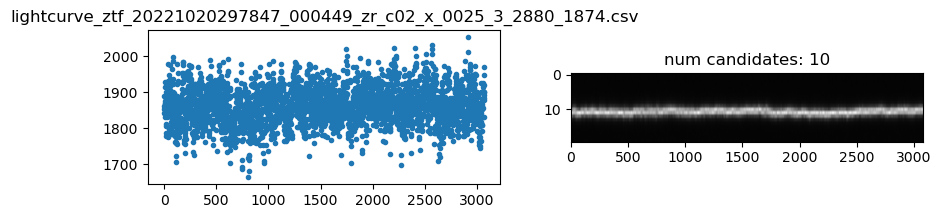

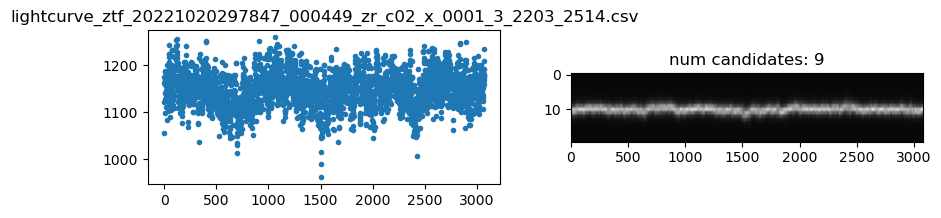

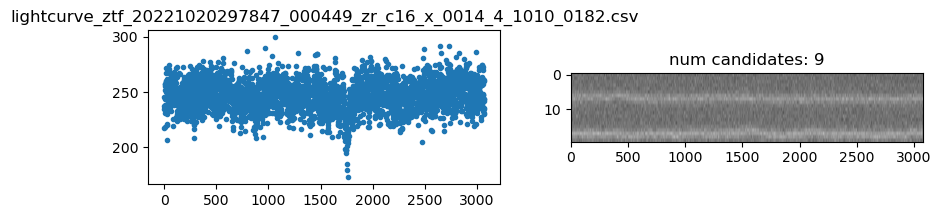

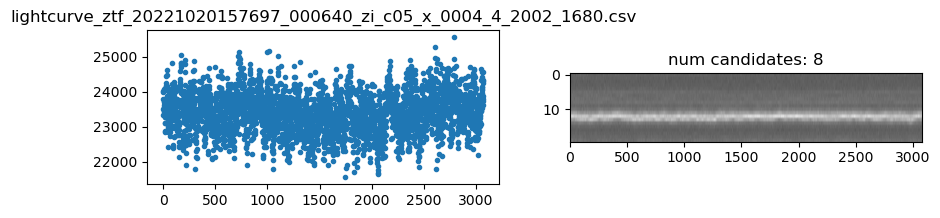

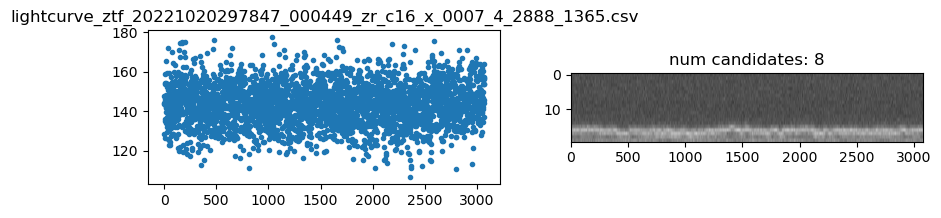

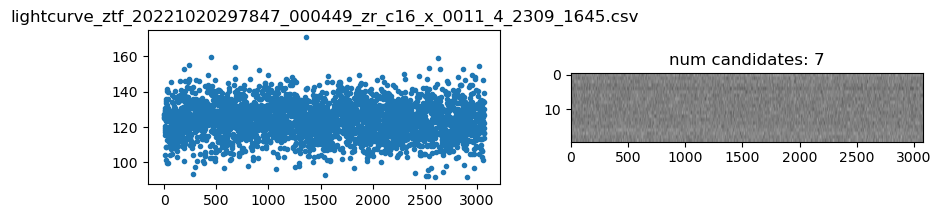

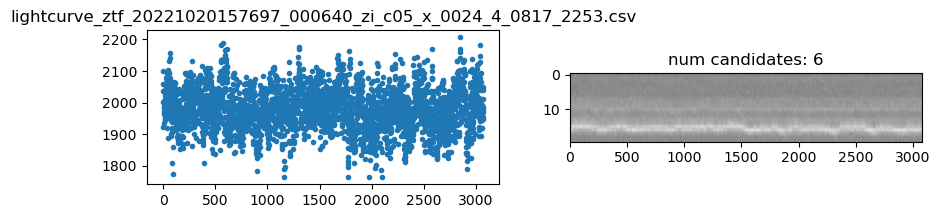

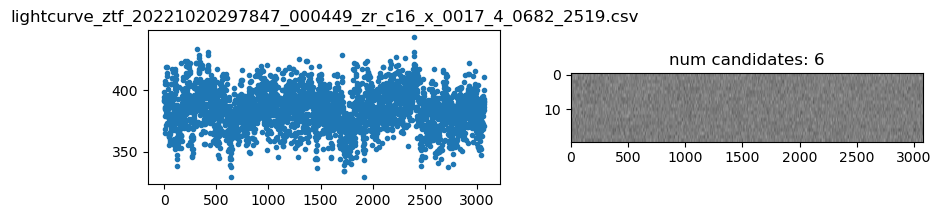

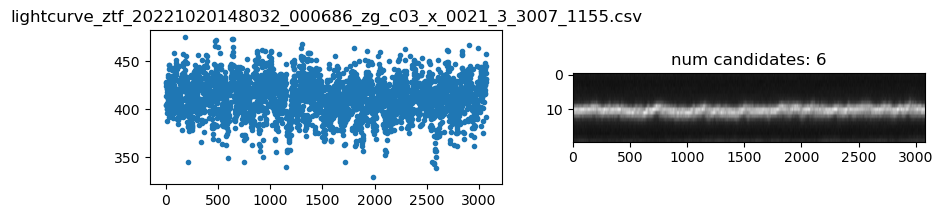

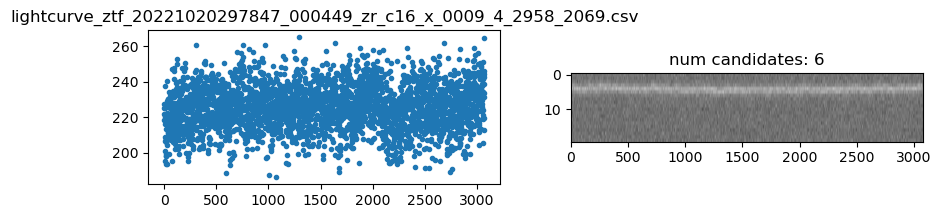

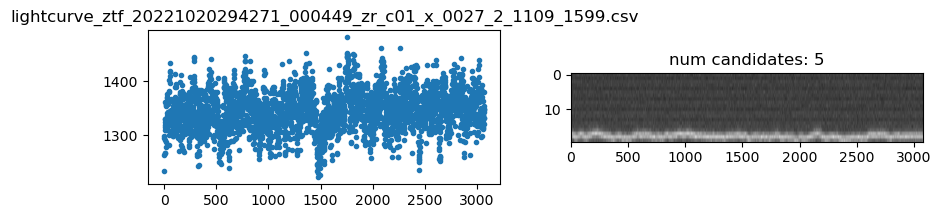

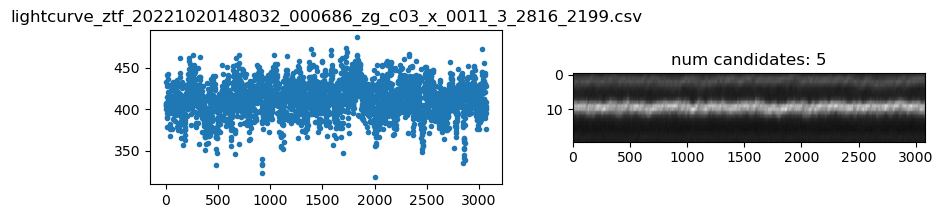

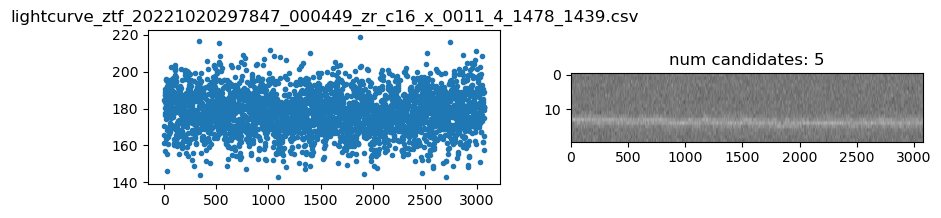

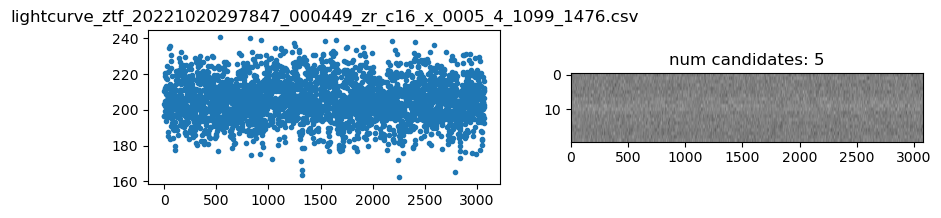

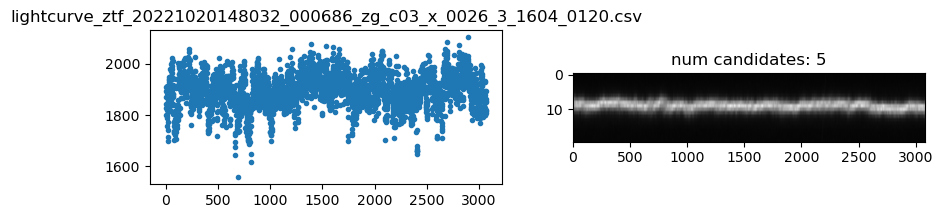

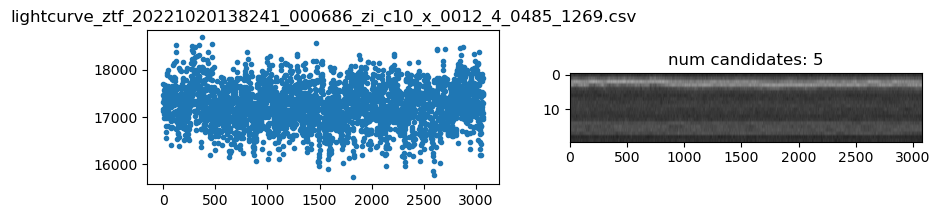

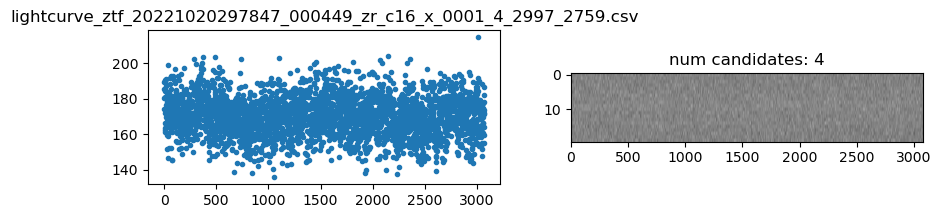

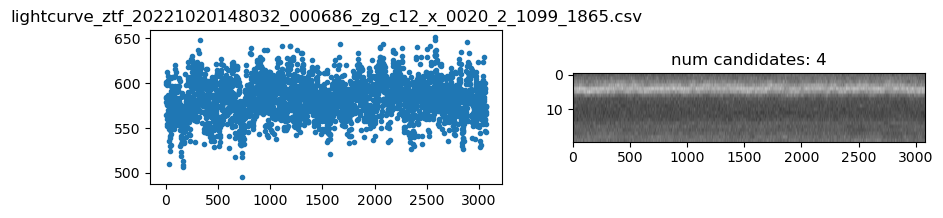

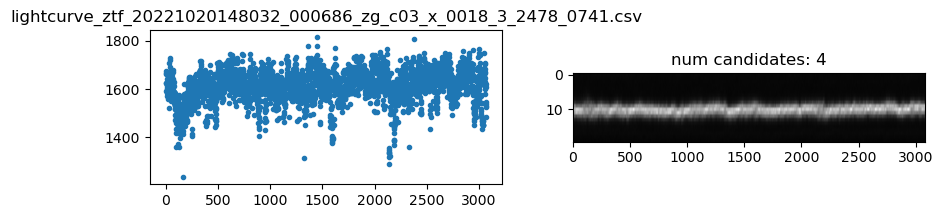

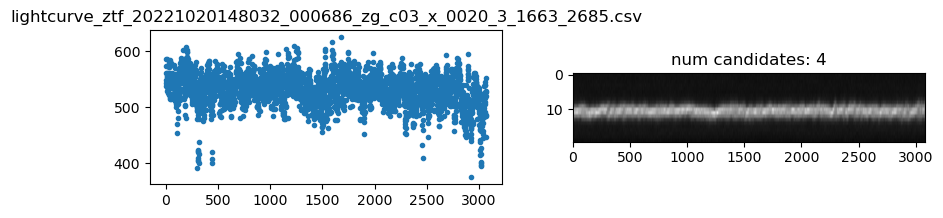

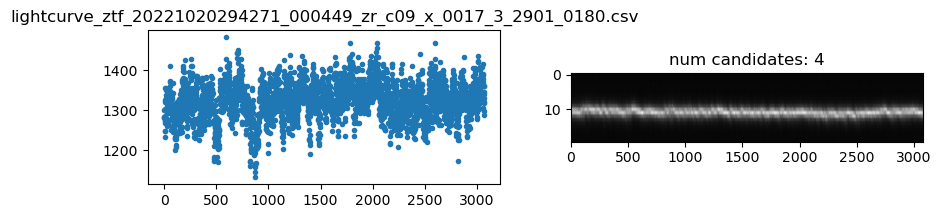

In [148]:
plt.rcParams["figure.figsize"] = (5, 2)
for i, lightcurve in pd.DataFrame(alist).sort_values(1, ascending=False)[:30].iterrows():
        # print("num candidates below: ",lightcurve[1] )
        # try:
        if lightcurve[0][:50]!='lightcurve_ztf_20221020138241_000686_zi_c01_x_0000':
            loaded = pd.read_csv(lcpath+lightcurve[0])
            fitsfile = fits.open('/lustre/lrspec/ZTF_data/2022/1020/'+lightcurve[0][11:50]+'.fits.fz')
            quad = filename[51]
            realimage = fitsfile[quad].data
            # print(realimage)
            fig, ax = plt.subplots(1, 2, figsize=(10,2))
            # fig, ax = plt.subplots(1, 3, figsize=(10,2))

            ax[0].plot(loaded['flux_hap_2'][:-10], '.')
            ax[0].set_title(lightcurve[0])
            
            xcoord = int(lightcurve[0][-13:-9])
            ycoord= int(lightcurve[0][-8:-4])
            ax[1].imshow(realimage[:,xcoord-10:xcoord+10].T, aspect=30, cmap="gist_gray")
            ax[1].set_title("num candidates: "+str(lightcurve[1] ))
            # ax[2].plot(loaded['max_col'][:-10], '.')
            # ax[2].set_title('max_col')
            fig.show()
            # plt.close()
            # break
        # except:
            # break
            # print(lightcurve[0])